In [6]:
import pandas as pd
df = pd.read_csv(r"C:\Users\HP\Downloads\e commerce dataset (1).csv",encoding='latin1')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [8]:

print("size of data (Rows, Columns):", df.shape)


print("\nmissing values:")
print(df.isnull().sum())


डेटाचा आकार (Rows, Columns): (9994, 21)

मिसिंग व्हॅल्यूजची संख्या:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [12]:

df = df.drop_duplicates()
print("duplicate data finds successful!")


print("\n columns and their data type:")
df.dtypes


duplicate data finds successful!

 columns and their data type:


Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [14]:
total_sales = df['Sales'].sum() if 'Sales' in df.columns else df['sales'].sum()
total_profit = df['Profit'].sum() if 'Profit' in df.columns else df['profit'].sum()

print(f"total sales of company: {total_sales}")
print(f"total profit of company: {total_profit}")

total sales of company: 2297200.8603000003
total profit of company: 286397.0217


In [16]:

category_column = 'Category' if 'Category' in df.columns else 'category'

if category_column in df.columns:
    category_summary = df.groupby(category_column)[['Sales', 'Profit']].sum()
    print("---category wise profit and sales")
    print(category_summary)
else:
    print("dose not match category column , going to next step.")


product_column = 'Product Name' if 'Product Name' in df.columns else ('product_name' if 'product_name' in df.columns else 'Sub-Category')

if product_column in df.columns:
    top_products = df.groupby(product_column)['Profit'].sum().sort_values(ascending=False).head(5)
    print("\n--- top 5 product to give more profit ---")
    print(top_products)


---category wise profit and sales
                       Sales       Profit
Category                                 
Furniture        741999.7953   18451.2728
Office Supplies  719047.0320  122490.8008
Technology       836154.0330  145454.9481

--- top 5 product to give more profit ---
Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Name: Profit, dtype: float64


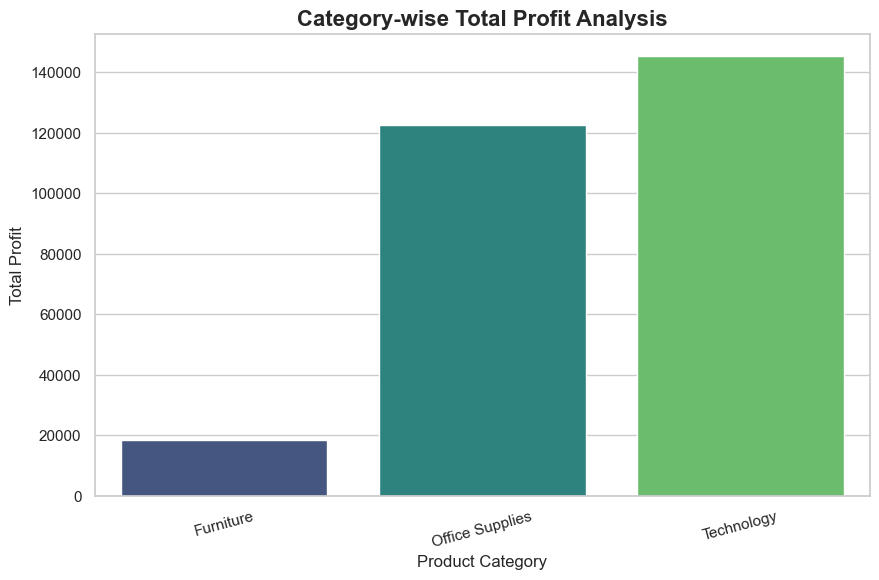

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns


profit_col = [col for col in df.columns if col.lower() == 'profit']
cat_col = [col for col in df.columns if col.lower() == 'category']


if profit_col and cat_col:
    p_name = profit_col[0]
    c_name = cat_col[0]
    
    
    sns.set_theme(style="whitegrid")
    plt.figure(figsize=(10, 6))
    
   
    sns.barplot(
        x=c_name,
        y=p_name,
        data=df,
        estimator=sum,
        errorbar=None,
        hue=c_name,
        palette="viridis",
        legend=False
    )
    
    plt.title('Category-wise Total Profit Analysis', fontsize=16, fontweight='bold')
    plt.xlabel('Product Category', fontsize=12)
    plt.ylabel('Total Profit', fontsize=12)
    plt.xticks(rotation=15) 
   
    plt.show()
else:
    print("Error: 'Profit' or 'Category' columns could not be identified in the dataset.")
    print("Available dataset schema fields are:", list(df.columns))

    
    
    
   